# 01 · Exploring the M5 (Walmart) data

**Context:** the *M5 Forecasting* competition dataset contains daily unit sales for 3,049 products across 10 Walmart stores in three U.S. states (California, Texas, and Wisconsin), along with an events calendar and weekly prices. Each product-store combination is a **time series**: 30,490 series in total.

**Goal of this notebook:** understand what the data looks like before modeling, and define the **evaluation protocol** that will be used for all the models in the project.

**Questions this notebook answers**
1. How is the dataset organized and what period does it cover?
2. What seasonality and which events affect sales?
3. How intermittent is the demand (many days with no sales)?
4. Do all the series start at the same time?
5. What is the relationship between price and sales?
6. How will each model be evaluated?

## 1. Setup

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import (
    ensure_m5, load_calendar, load_prices, load_sales, day_columns,
    sample_series, to_long, SEED,
)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

## 2. Loading the data

Three files are read: the **calendar** (date, day of the week, events, and SNAP social benefit days), the weekly **prices** of each product in each store, and the **daily sales** in wide format (one column per day). The `evaluation` version of the sales is used (up to day 1,941) and, if it is not available, the `validation` version (up to day 1,913); the first time, `ensure_m5()` unzips or downloads the files.

In [2]:
carpeta = ensure_m5()
calendario = load_calendar(carpeta)
precios = load_prices(carpeta)
ventas = load_sales(carpeta)

dias = day_columns(ventas)
Y = ventas[dias].to_numpy()

print("Series:", len(ventas), "| days with sales:", len(dias))
if len(dias) < 1941:
    print("WARNING: there are fewer than 1,941 days (validation version); the protocol windows are computed using the last available day.")
print("Price rows:", len(precios), "| calendar days:", len(calendario))
ventas.iloc[:3, :10]

Series: 30490 | days with sales: 1941
Price rows: 6841121 | calendar days: 1969


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


### 2.1 Hierarchy and period

The series can be grouped by store, state, department, and category. This hierarchy is useful for understanding how sales are distributed, although in this project forecasts are made at the level of each product and store.

In [3]:
jerarquia = pd.Series({
    "series (product × store)": len(ventas),
    "products": ventas["item_id"].nunique(),
    "departments": ventas["dept_id"].nunique(),
    "categories": ventas["cat_id"].nunique(),
    "stores": ventas["store_id"].nunique(),
    "states": ventas["state_id"].nunique(),
})
print(jerarquia.to_string())

fechas = calendario.set_index("d").loc[dias, "date"]
print(f"\nFirst day: {fechas.iloc[0].date()} | last day with sales: {fechas.iloc[-1].date()} | days: {len(dias)}")

pd.crosstab(ventas["cat_id"], ventas["store_id"])

series (product × store)    30490
products                     3049
departments                     7
categories                      3
stores                         10
states                          3

First day: 2011-01-29 | last day with sales: 2016-05-22 | days: 1941


store_id,CA_1,CA_2,CA_3,CA_4,TX_1,TX_2,TX_3,WI_1,WI_2,WI_3
cat_id,,,,,,,,,,
HOBBIES,565,565,565,565,565,565,565,565,565,565
HOUSEHOLD,1047,1047,1047,1047,1047,1047,1047,1047,1047,1047
FOODS,1437,1437,1437,1437,1437,1437,1437,1437,1437,1437


## 3. Total sales over time

The sales of all series are summed for each day, and the 28-day moving average is shown, which removes the day-of-week effect and reveals the trend and the annual seasonality.

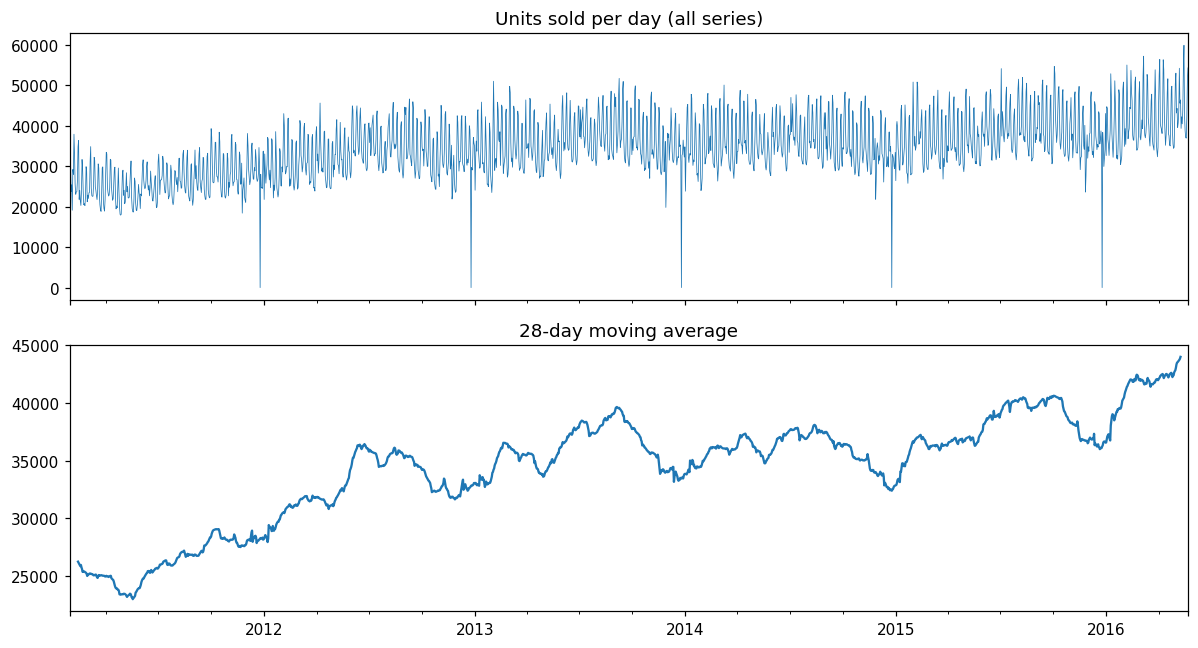

Days with very low sales (less than 30% of the median):
            units dia_semana
2011-12-25     13     Sunday
2012-12-25     11    Tuesday
2013-12-25     20  Wednesday
2014-12-25     20   Thursday
2015-12-25     14     Friday


In [4]:
fechas_d = pd.to_datetime(fechas.to_numpy())
total_diario = pd.Series(Y.sum(axis=0), index=fechas_d)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
total_diario.plot(ax=axes[0], linewidth=0.5)
axes[0].set_title("Units sold per day (all series)")
total_diario.rolling(28, center=True).mean().plot(ax=axes[1])
axes[1].set_title("28-day moving average")
plt.tight_layout()
plt.show()

cierres = total_diario[total_diario < 0.3 * total_diario.median()]
print("Days with very low sales (less than 30% of the median):")
print(cierres.to_frame("units").assign(dia_semana=cierres.index.day_name()))

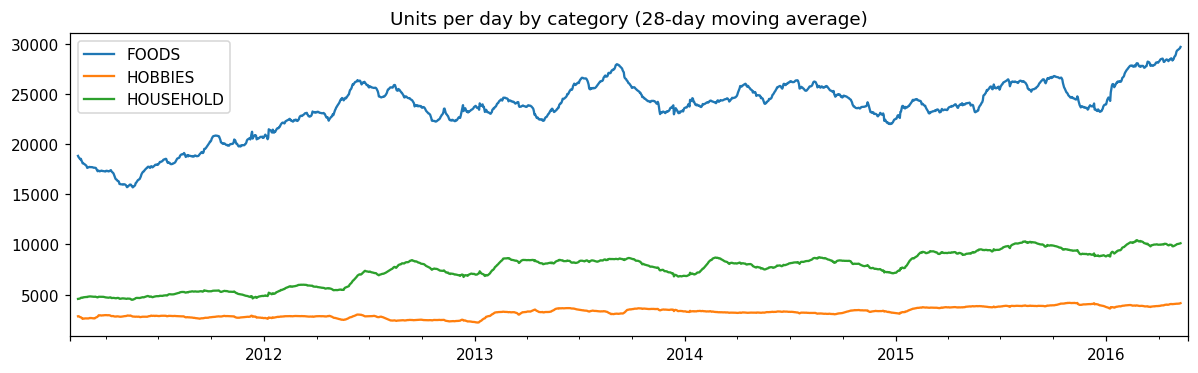

Share of units sold: {'FOODS': 0.686, 'HOBBIES': 0.093, 'HOUSEHOLD': 0.221}


In [5]:
por_categoria = pd.DataFrame(
    {cat: Y[(ventas["cat_id"] == cat).to_numpy()].sum(axis=0) for cat in sorted(ventas["cat_id"].unique())},
    index=fechas_d,
)
ax = por_categoria.rolling(28, center=True).mean().plot(figsize=(11, 3.5))
ax.set_title("Units per day by category (28-day moving average)")
plt.tight_layout()
plt.show()

participacion = (por_categoria.sum() / por_categoria.sum().sum()).round(3)
print("Share of units sold:", participacion.to_dict())

### 3.1 Weekly and annual seasonality

The **weekly index** compares the sales of each day of the week with the daily average. The **monthly index** does the same for each month of the year, and is computed over the available days, so incomplete years have a slight influence.

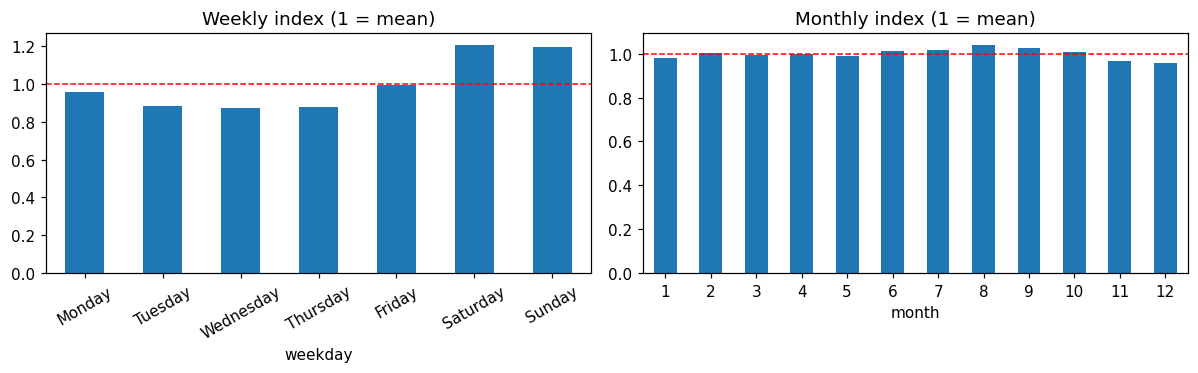

Weekly index:
weekday
Monday       0.957
Tuesday      0.885
Wednesday    0.874
Thursday     0.879
Friday       0.996
Saturday     1.210
Sunday       1.198

Monthly index (month 1 = january):
month
1     0.981
2     1.005
3     0.996
4     0.999
5     0.989
6     1.015
7     1.019
8     1.043
9     1.029
10    1.007
11    0.965
12    0.956


In [6]:
cal = calendario.set_index("d").loc[dias].copy()
cal["total"] = total_diario.to_numpy()

indice_semana = cal.groupby("weekday")["total"].mean() / cal["total"].mean()
orden = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
indice_semana = indice_semana.reindex(orden)

indice_mes = cal.groupby("month")["total"].mean() / cal["total"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
indice_semana.plot.bar(ax=axes[0], rot=30)
axes[0].axhline(1, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Weekly index (1 = mean)")
indice_mes.plot.bar(ax=axes[1], rot=0)
axes[1].axhline(1, color="red", linestyle="--", linewidth=1)
axes[1].set_title("Monthly index (1 = mean)")
plt.tight_layout()
plt.show()

print("Weekly index:")
print(indice_semana.round(3).to_string())
print("\nMonthly index (month 1 = january):")
print(indice_mes.round(3).to_string())

## 4. Events and SNAP days

To measure the effect of an event without confounding it with the trend and the day of the week, the **relative sales** are computed: the day's total divided by the 28-day moving average, and then corrected by the weekly index. A value of 1 indicates a normal day. This is a description, not a causal effect: an event may coincide with other things, such as a season.

In [7]:
rel = cal["total"] / cal["total"].rolling(28, center=True).mean()
cal["rel"] = rel / rel.groupby(cal["weekday"]).transform("mean")

evento = cal[cal["event_name_1"].notna()]
por_tipo = evento.groupby("event_type_1")["rel"].agg(["count", "mean"]).round(3)
print("Relative sales by event type (1 = normal day):")
print(por_tipo)

por_evento = evento.groupby("event_name_1")["rel"].agg(["count", "mean"])
por_evento = por_evento[por_evento["count"] >= 4].sort_values("mean").round(3)
print("\nEvents with the lowest relative sales:")
print(por_evento.head(5))
print("\nEvents with the highest relative sales:")
print(por_evento.tail(5))

Relative sales by event type (1 = normal day):
              count   mean
event_type_1              
Cultural         37  0.931
National         51  0.896
Religious        54  1.013
Sporting         15  1.007

Events with the lowest relative sales:
              count   mean
event_name_1              
Christmas         5  0.001
Thanksgiving      5  0.734
NewYear           5  0.817
Mother's day      6  0.875
Father's day      4  0.885

Events with the highest relative sales:
                   count   mean
event_name_1                   
NBAFinalsStart         5  1.047
VeteransDay            5  1.057
OrthodoxChristmas      5  1.060
Chanukah End           5  1.063
LaborDay               5  1.226


**SNAP days** are days on which beneficiaries of the food assistance program can use their benefits in the stores of each state. The relative sales of the stores in each state are compared on SNAP days and on non-SNAP days.

In [8]:
filas = []
for estado in sorted(ventas["state_id"].unique()):
    total_e = pd.Series(Y[(ventas["state_id"] == estado).to_numpy()].sum(axis=0), index=cal.index)
    r = total_e / total_e.rolling(28, center=True).mean()
    r = r / r.groupby(cal["weekday"]).transform("mean")
    snap = cal[f"snap_{estado}"] == 1
    filas.append({"state": estado, "snap_days_%": 100 * snap.mean(),
                  "relative_sale_snap": r[snap].mean(), "relative_sale_with_no_snap": r[~snap].mean()})
pd.DataFrame(filas).round(3)

,state,snap_days_%,relative_sale_snap,relative_sale_with_no_snap
0,CA,32.973,1.054,0.973
1,TX,32.973,1.073,0.964
2,WI,32.973,1.131,0.936


## 5. Sample of series for the project

Modeling all 30,490 series would require far more compute than is available on a CPU. For that reason, the project's models are trained and evaluated on a **reproducible sample of 60 series per store (600 in total)**, chosen at random with a fixed seed. We check that the sample resembles the full dataset.

In [9]:
muestra = sample_series(ventas, n_per_store=60, seed=SEED)
Y_m = muestra[dias].to_numpy()

comparacion = pd.DataFrame({
    "category_total_%": 100 * ventas["cat_id"].value_counts(normalize=True),
    "category_sample_%": 100 * muestra["cat_id"].value_counts(normalize=True),
}).round(1)
print(comparacion)
print()
print(f"Proportion of days with no sales — total: {(Y == 0).mean():.3f} | sample: {(Y_m == 0).mean():.3f}")
print(f"Mean sales per series per day — total: {Y.mean():.3f} | sample: {Y_m.mean():.3f}")
print("Series in the sample:", len(muestra))

           category_total_%  category_sample_%
cat_id                                        
FOODS                  47.1               48.0
HOUSEHOLD              34.3               33.5
HOBBIES                18.5               18.5

Proportion of days with no sales — total: 0.680 | sample: 0.682
Mean sales per series per day — total: 1.131 | sample: 1.122
Series in the sample: 600


## 6. Demand intermittency

Many series have **intermittent demand**: on most days nothing is sold, and on the days with sales, the quantities are small. This makes forecasting harder and is the reason why the usual metrics, such as percentage error, are not suitable (they would divide by zero).

Each series is classified with the Syntetos and Boylan (2005) scheme, based on two measures computed from the first sale:

- **ADI** (average demand interval): how many days pass, on average, between one day with sales and the next.
- **CV²**: how much the quantities sold vary, relative to their mean (squared coefficient of variation), considering only the days with sales.

With the usual thresholds of ADI = 1.32 and CV² = 0.49, the series are divided into four types: **smooth** (frequent and regular sales), **erratic** (frequent, but with variable quantities), **intermittent** (sporadic, with regular quantities), and **lumpy** (sporadic and with highly variable quantities).

In [10]:
inicio = np.where((Y > 0).any(axis=1), (Y > 0).argmax(axis=1), Y.shape[1])

adi = np.full(len(Y), np.nan)
cv2 = np.full(len(Y), np.nan)
for i in range(len(Y)):
    y = Y[i, inicio[i]:]
    nz = y[y > 0]
    if len(nz) > 0:
        adi[i] = len(y) / len(nz)
        cv2[i] = (nz.std() / nz.mean()) ** 2

tipo = np.select(
    [np.isnan(adi), (adi < 1.32) & (cv2 < 0.49), (adi < 1.32), (cv2 < 0.49)],
    ["with no sales", "smooth", "erratic", "intermittent"],
    default="irregular",
)

unidades = Y.sum(axis=1)
tabla_tipo = pd.DataFrame({"series": pd.Series(tipo).value_counts()})
tabla_tipo["series_%"] = 100 * tabla_tipo["series"] / len(Y)
tabla_tipo["units_%"] = 100 * pd.Series(unidades).groupby(tipo).sum().reindex(tabla_tipo.index) / unidades.sum()
tabla_tipo.round(1)

,series,series_%,units_%
intermittent,22155,72.7,33.8
irregular,5572,18.3,23.8
smooth,1903,6.2,28.6
erratic,860,2.8,13.8


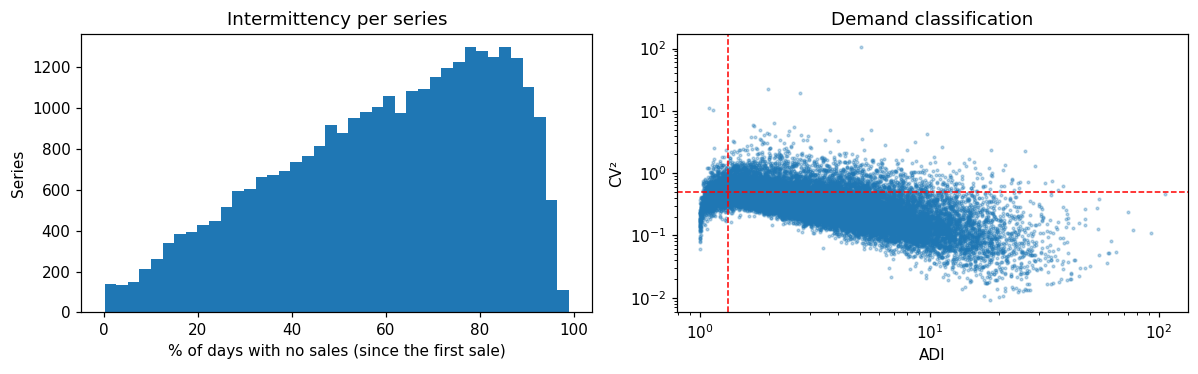

Overall proportion of days with no sales: 68.0%
Median % of days with no sales per series (since the first sale): 63.3 %


In [11]:
dias_activos = Y.shape[1] - inicio
pct_ceros = 1 - (Y > 0).sum(axis=1) / np.maximum(dias_activos, 1)
validas = dias_activos > 0

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(100 * pct_ceros[validas], bins=40)
axes[0].set_xlabel("% of days with no sales (since the first sale)")
axes[0].set_ylabel("Series")
axes[0].set_title("Intermittency per series")
axes[1].scatter(adi, cv2, s=3, alpha=0.3)
axes[1].axvline(1.32, color="red", linestyle="--", linewidth=1)
axes[1].axhline(0.49, color="red", linestyle="--", linewidth=1)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("ADI")
axes[1].set_ylabel("CV²")
axes[1].set_title("Demand classification")
plt.tight_layout()
plt.show()

print(f"Overall proportion of days with no sales: {(Y == 0).mean():.1%}")
print(f"Median % of days with no sales per series (since the first sale): {100 * np.median(pct_ceros[validas]):.1f} %")

## 7. Series that start late

Not all series have a complete history: many products are added to a store after the first day, and until then their sales are recorded as zero. Those initial zeros **are not zero demand**, they are products that were not yet being sold, and if they are treated as real demand they distort the models and the metrics. That is why the project's metric counts the past from the first sale.

Series that start after the first day: 23511 (77.1%)
Series with at least 1 year of initial zeros: 13420 (44.0%)
Series with no sales: 0


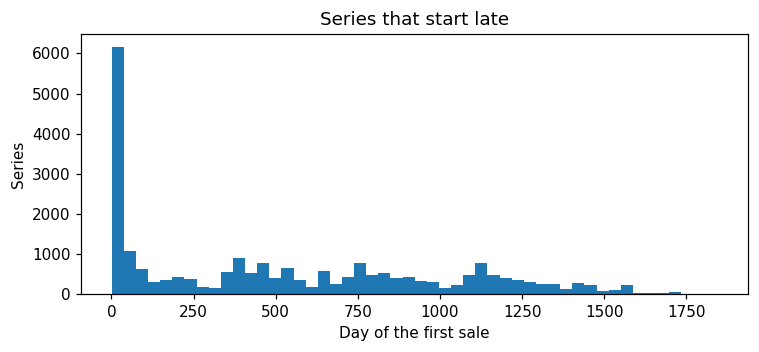

In [12]:
tarde = inicio > 0
print(f"Series that start after the first day: {tarde.sum()} ({tarde.mean():.1%})")
print(f"Series with at least 1 year of initial zeros: {(inicio > 365).sum()} ({(inicio > 365).mean():.1%})")
print(f"Series with no sales: {(inicio == Y.shape[1]).sum()}")

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.hist(inicio[tarde], bins=50)
ax.set_xlabel("Day of the first sale")
ax.set_ylabel("Series")
ax.set_title("Series that start late")
plt.tight_layout()
plt.show()

## 8. Prices and sales

Prices change little, and promotions can be seen as temporary drops. First we measure how much prices vary, and then, descriptively, how they relate to sales in the sample: for each series and week, the relative price (the week's price divided by the median price of that series) and the relative sales (the week's sales divided by that series' weekly average).

This is a description and not an elasticity: discounts often coincide with events and seasons, so part of the relationship may be due to that.

In [13]:
pares = muestra[["item_id", "store_id"]].astype(str).drop_duplicates()
precios_m = precios.assign(item_id=precios["item_id"].astype(str), store_id=precios["store_id"].astype(str)).merge(pares)

g = precios_m.groupby(["store_id", "item_id"])["sell_price"]
cambia = g.nunique() > 1
variacion = precios_m.sort_values("wm_yr_wk").groupby(["store_id", "item_id"])["sell_price"].pct_change().dropna()
print(f"Series in the sample with more than one price: {cambia.mean():.1%}")
print(f"Weeks in which the price changes: {(variacion != 0).mean():.1%}")
print(f"Among the changes, median absolute change: {100 * variacion[variacion != 0].abs().median():.1f} %")

Series in the sample with more than one price: 73.2%
Weeks in which the price changes: 1.2%
Among the changes, median absolute change: 8.4 %


In [14]:
largo = to_long(muestra, calendario, precios)
sem = largo.groupby(["id", "wm_yr_wk"], observed=True).agg(
    ventas=("ventas", "sum"), precio=("sell_price", "first"), n_dias=("ventas", "size")
).reset_index()
sem = sem[(sem["n_dias"] == 7) & sem["precio"].notna()].copy()

sem["rel_price"] = sem["precio"] / sem.groupby("id", observed=True)["precio"].transform("median")
sem["ventas_rel"] = sem["ventas"] / sem.groupby("id", observed=True)["ventas"].transform("mean")

grupos = pd.cut(sem["rel_price"], [0, 0.90, 0.97, 1.03, np.inf],
                labels=["drops > 10 %", "drops 3-10 %", "usual (±3 %)", "rises > 3 %"])
tabla = sem.groupby(grupos, observed=True).agg(weeks=("ventas_rel", "size"), relative_sales=("ventas_rel", "mean"))
tabla["weeks_%"] = 100 * tabla["weeks"] / tabla["weeks"].sum()
tabla.round(3)

,weeks,relative_sales,weeks_%
rel_price,,,
drops > 10 %,5473,1.251,4.083
drops 3-10 %,9138,1.145,6.818
usual (±3 %),104276,0.983,77.797
rises > 3 %,15149,0.936,11.302


## 9. Evaluation protocol

It is defined **before training any model**, so that all of them are compared under the same conditions and the evaluation is not tuned to the results.

**Data:** the sample of 600 series (60 per store, seed 42) over the available sales.

**Horizon and windows:** forecasts cover **28 days**, as in the competition, from a given origin and without any information after it. The last two available 28-day windows are used:
- **Validation:** the second-to-last window. It is used to compare model variants and choose hyperparameters.
- **Test:** the last window. It is used **only once**, at the end, with the already chosen model retrained on the data up to the test origin.

With the `evaluation` version (1,941 days), validation is days 1,886 to 1,913 and test is days 1,914 to 1,941; with the `validation` version (1,913 days), validation is days 1,858 to 1,885 and test is days 1,886 to 1,913. The next cell computes the windows from the loaded data.

The baselines and the statistical model, which have no hyperparameters to choose at this stage, are evaluated on both windows.

In [15]:
HORIZONTE = 28
T = len(dias)  # último día disponible

ventanas = {
    "validation": (T - 2 * HORIZONTE + 1, T - HORIZONTE),
    "test": (T - HORIZONTE + 1, T),
}
for nombre, (ini, fin) in ventanas.items():
    print(f"{nombre:>10}: day {ini} to {fin} ({fechas_d[ini - 1].date()} to {fechas_d[fin - 1].date()}) | origin on day {ini - 1}")

validation: day 1886 to 1913 (2016-03-28 to 2016-04-24) | origin on day 1885
      test: day 1914 to 1941 (2016-04-25 to 2016-05-22) | origin on day 1913


**What is known in advance:** the calendar and the prices for the 28 days to be forecast. In M5, future prices are published in advance, and that is what is assumed in this project. Sales after the origin are not used.

**Metrics (only two):**
- **RMSSE (scaled error):** root mean squared error of the forecast, divided by the mean squared error of a naive forecast (repeating the previous day) over the past of the same series, and with a square root. It is counted from the first sale. **A value below 1 means the model makes fewer errors than the naive forecast *in the past of that series*; it is not a direct comparison with the naive forecast over the period being forecast.** It is dimensionless, so series of different scales can be averaged, and it works with intermittent demand. The **simple average** across series is reported (not weighted by revenue, as in the competition's WRMSSE).
- **MAE (mean absolute error):** average absolute difference between actual and forecast sales, in units per series per day. It is easy to interpret, but it depends on the scale of the series.

Series with no sales before the origin (or with no variation) have no scale and are left out of the RMSSE; the number of such series is reported. The MAE is computed over all series.

The two errors are reported together because they complement each other: the RMSSE penalizes large errors more and allows comparing different series, and the MAE indicates the typical error in units.

## 10. Conclusions

- **Structure:** 30,490 series (3,049 products in 10 stores across 3 states), with daily sales from January 29, 2011 to May 22, 2016 (1,941 days). All stores have the same assortment: 1,437 FOODS products, 1,047 HOUSEHOLD products, and 565 HOBBIES products. FOODS accounts for 68.6% of the units sold, HOUSEHOLD for 22.1%, and HOBBIES for 9.3%.
- **Trend and scale by category:** in the 28-day moving average, the sales of the three categories fluctuate and appear to grow over time. FOODS moves between roughly 20,000 and 30,000 units per day, HOUSEHOLD between 5,000 and 10,000, and HOBBIES between 2,000 and 4,000 (approximate values, read from the chart).
- **Strong weekly seasonality:** on Saturday (1.21) and Sunday (1.20) about 20% more is sold than the average, and from Tuesday to Thursday (0.87 to 0.89) about 12% less. Between the best and the worst day, the difference is about 38%. It is the most pronounced pattern in the data and the models have to capture it.
- **Weak annual seasonality and growing trend:** the monthly index ranges from 0.96 (December) to 1.04 (August). It is not corrected for the trend: in all three categories daily sales appear to grow over time, so part of that variation may reflect growth and not seasonality.
- **Events:** on December 25 the stores practically do not sell (between 11 and 20 units in total across the 30,490 series), which is a closure and not low demand. Among the events with at least 4 occurrences, Thanksgiving (0.73), New Year's Day (0.82), and Mother's Day (0.88) sell less than a normal day, and Labor Day (1.23) sells more. The averages by type (national 0.90 with 51 events, cultural 0.93 with 37, religious 1.01 with 54, and sporting 1.01 with 15) mix very different events; in particular, the December 25 closure may drag down the average of the type it belongs to, so they are less informative than the per-event values. Each event has few occurrences (4 to 6), so the individual values are noisy.
- **SNAP days:** in all three states 33% of the days are SNAP days, and more is sold on those days: relative sales are 1.08 times those of non-SNAP days in California (1.054 versus 0.973), 1.11 in Texas, and 1.21 in Wisconsin. This is a descriptive difference that does not separate the effect of the benefit from the effect of the time of the month in which it falls.
- **Intermittency:** 68.0% of the daily observations are zero, and the median share of days with no sales per series, counted from its first sale, is 63.3%. According to the Syntetos and Boylan classification, 72.7% of the series are intermittent and 18.3% are lumpy: 91% have sporadic demand, and those series account for 57.6% of the units. Only 6.2% are smooth and 2.8% erratic, but they concentrate 42.4% of the units.
- **Series that start late:** 77.1% of the series have their first sale after the first day, and 44.0% have at least one year of initial zeros. No series is completely empty. Those zeros are not zero demand; that is why the RMSSE counts the past from the first sale, and why the age of each series is relevant information for the models.
- **Prices:** 73.2% of the series in the sample change price at some point, but the price changes in only 1.2% of the weeks (median absolute change: 8.4%). Weeks with a price drop of more than 10% (4.1% of the weeks) have sales 25% higher than usual for the series (1.25), those with a drop of 3 to 10% (6.8% of the weeks) have 15% more (1.15), and weeks with a rise of more than 3% (11.3%) have 6% less (0.94). 77.8% of the weeks have a usual price (within ±3% of the series' median). This is a descriptive and not a causal relationship: discounts coincide with events and with the age of each product.
- **Representativeness of the sample:** the 600 series reproduce the composition by category (FOODS 48.0% versus 47.1% in the total) and the intermittency (68.2% of days with no sales versus 68.0%).
- **Implications for modeling:**
  - The models have to use the day of the week. The calendar (with a flag for December 25), SNAP days, and prices may provide additional information.
  - Since sales appear to grow over time, the distant history describes current demand less well: it is advisable for the models to give more weight to recent data (short moving averages, lags, and series age).
  - With such sporadic demand, the MAE and the RMSSE may rank the models differently: the MAE is minimized by forecasting the median of each series (which in many is zero) and the RMSSE, based on squared errors, by forecasting the mean. The two errors will be read together.
  - The evaluation windows are validation (March 28 to April 24, 2016, days 1,886 to 1,913) and test (April 25 to May 22, days 1,914 to 1,941). They do not include the holidays with the greatest impact (Christmas, Thanksgiving, or New Year's Day): validation has no events at all and test has four minor ones (Pesach End, Orthodox Easter, Cinco de Mayo, and Mother's Day). For that reason events will weigh little in the metrics, although they do matter when training.
- **Limitations:** the statistics in this notebook use all the available days, including the validation and test windows. They are not used to tune any model (the models only see data prior to each origin), but the demand-type classification in this notebook may differ from the one computed only with the history prior to each origin, as in the following notebooks. The tables of events, SNAP, and prices are descriptive and do not establish causal relationships, and the figures read from charts are approximate.